# 06 · Probes: where is the bottleneck, and how lean can the front end be?

Cheap experiments that answer questions before any big search (model/search_space.py).
All run on the same **raw-audio probe streams** (`model/probe_data.py`), so any front end or
any detector, ours or someone else's, sees exactly the same audio:

| stream | what | hours |
|---|---|---|
| `pos_<word>` | held-out-voice keyword clips at 0.3–5 m, simulated rooms, muffling, 0–25 dB ambience, 1.5–3.5 s apart | 0.4–0.7 each |
| `sim_convo` | simulated conversation over ambience (held-out voices/text) | 6 |
| `sim_hard` | every candidate word, partial phrase and near-miss, over ambience | 4.2 |
| `real_ami` | real far-field meetings (AMI), untouched | 8 |

**Metric:** miss rate (FRR) at a false-alarm rate set on the simulated negatives
(`sim_convo` + `sim_hard`), and the real false-alarm rate on AMI at that same threshold.
Even 60 s chunks are the validation half (early stopping), odd chunks the test half.

| probe | question | code |
|---|---|---|
| **P1** | Do published open-source wake-word models just work on our test conditions? Which is best? | `model/probe_pretrained.py` |
| **F** | Front-end bit diet: which bits/bands/rates can go, and what does each save? | `model/probe_frontend.py`, `model/frontend_var.py` |
| **P3** | Is a mel / float front end much better than the chip's? | (variants in F) |
| **P5** | What does a big pretrained speech representation buy on our data? | `model/probe_embed.py` |
| **P2** | Is model size the bottleneck? | F harness, wide TCN |

## Summary (night of 2026-10-27)

**1. Off-the-shelf models don't "just work" here, and that's mostly our test mix (P1).**
openWakeWord and microWakeWord, as shipped, miss 27–64% of keywords at 1 false alarm/h on
our simulated test streams (best: openWakeWord *alexa* 27%, microWakeWord *hey_jarvis*
32%). Within 0.6 m they miss only 6–11%; misses come from 2.5–5 m talkers, SNR below 0 dB
and muffled speech, which our test mix deliberately over-represents. Best of the two:
openWakeWord on alexa/hey_jarvis; microWakeWord (our size class, ~50 kB int8) close
behind and better on hey_mycroft (openWakeWord's mycroft model fails on our Piper voices).

**2. The bottleneck is the learned representation, not the front end's bits (P5, P6).**
On identical data and streams, misses at 5 / 10 false alarms/h:
TCN from scratch on chip features 61–69% / 53–57%;
frozen Google speech embedding + small head 24% / 19%;
**a 45k-param student on chip features distilled from that embedding + the same head
33% / 28%** (155k-param student: 29% / 26%). Distillation on simulated audio only (the
student never sees real speech) recovers most of the gap → that's tomorrow's training plan.

**3. Front end: cut the bits, add filter order (F, F2).** 66-word accuracy on held-out voices
(seed noise ±0.3 pt), today's chip = 52.4%:
* free cuts (no loss alone or combined, `lean5`): PCM 16→12 bits, coefficients Q2.14→Q2.8,
  filter state 22→18 bits, accumulator 24→20 bits (shift 2→4), feature code 8 bits at
  1/8 octave → 6 bits at 1/4 octave: **1,270 → 1,040 FF**, multiplier 770 → 482 cycles/sample;
* what hurts: PCM 8 bits (−6), state 14/12 bits (−10/−16), accumulator 16/12 bits (−8/−34),
  8 bands (−4.4), 12 bands (−1.5…−2.2), 8 kHz (−1.7), 1-octave codes (−3);
* what mel features have that our filters don't: **steeper band skirts**, not more bands
  (16-band mel = 40-band mel at 10 ms = 55.6–56.0%; float 2nd-order IIR 53.0%, float
  4th-order 54.9%, + power energy 55.7%). In the chip's integer arithmetic a 4th-order bank
  (two cascaded resonators per band) reaches **55.1–55.2%**; with the lean widths
  (`lean5o4`) it is **1,616 FF** (+346 vs today, ~1 tile) and fits the cycle budget
  (962/1024).
* bigger lever, not built: keep filter state in the PSRAM next to the audio ring buffer
  (~4 tiles → ~1–1.5 tiles for ~13% of QSPI bandwidth), which also makes 4th order and
  more bands nearly free in area.

**Front-end menu** (66-word accuracy, mean of 2 seeds; filterbank flip-flops):

| variant | what | FF | acc |
|---|---|---|---|
| `base` | today's chip | 1,270 | 52.4% |
| `lean5` | free bit cuts | 1,040 | 52.6% |
| `lean5o4b12` | lean bits, 4th order, 12 bands | 1,248 | 54.2% |
| `lean5o4` | lean bits, 4th order, 16 bands | 1,616 | 55.2% |
| `mel40_10ms` | float STFT mel reference (not chip) | – | 56.0% |

**Recommendation:** front end = `lean5o4` (or `lean5o4b12` at today's area);
detector = distilled student on chip features; next experiments in
"What to do next" at the end.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
R = ROOT / "data/probe/results"
S = ROOT / "data/probe/streams"
pd.set_option("display.width", 200)
FAS = (0.5, 1.0, 2.0, 5.0, 10.0)

## P1 · Off-the-shelf models, as published

openWakeWord 0.4 (frozen Google speech embedding + per-word head, trained on synthetic TTS
positives and ~30k h negatives) and microWakeWord v2 (ESPHome's ~50 kB int8 streaming CNN,
trained on Piper-synthetic positives). Our simulator renders their wake words with our
held-out voices; nothing is retrained. `frr@x` = miss rate at x false alarms/h on our
simulated negatives; `real_fa@x` = real AMI false alarms/h at that threshold;
`frr@default` = at the threshold the project ships.

In [2]:
p1 = json.loads((R / "pretrained.json").read_text())
rows = []
for k, r in p1.items():
    sys_, w = k.split("/")
    rows.append({"model": sys_, "word": w, **{f"frr@{fa}": r[f"frr@{fa}"] for fa in FAS},
                 **{f"real_fa@{fa}": r[f"real_fa@{fa}"] for fa in (1.0, 5.0)},
                 "frr@real1": r["frr@real1.0"], "frr@default": r.get("frr@default"),
                 "sim_fa@default": r.get("sim_fa@default"), "real_fa@default": r.get("real_fa@default")})
p1df = pd.DataFrame(rows).sort_values("frr@1.0")
p1df.round(3)

,model,word,frr@0.5,frr@1.0,frr@2.0,frr@5.0,frr@10.0,real_fa@1.0,real_fa@5.0,frr@real1,frr@default,sim_fa@default,real_fa@default
4,openWakeWord,alexa,0.290,0.266,0.234,0.193,0.174,0.80,1.74,0.249,0.186,6.69,3.08
1,microWakeWord,hey_jarvis,0.371,0.325,0.267,0.211,0.190,0.39,2.85,0.267,0.408,0.30,0.13
2,microWakeWord,hey_mycroft,0.380,0.366,0.298,0.228,0.168,0.26,1.16,0.288,0.317,1.42,0.65
3,microWakeWord,okay_nabu,0.586,0.449,0.409,0.327,0.266,0.26,0.91,0.325,0.491,0.61,0.13
0,microWakeWord,alexa,0.546,0.476,0.435,0.329,0.287,0.26,1.81,0.370,0.452,1.62,0.26
5,openWakeWord,hey_jarvis,0.703,0.624,0.341,0.179,0.139,0.13,0.53,0.160,0.179,4.91,0.53
6,openWakeWord,hey_mycroft,0.696,0.636,0.581,0.510,0.450,0.40,2.14,0.584,0.492,6.38,2.54


### Misses by condition

Per-clip conditions from `pos_<word>_meta.json` (same seeds as the streams). Distance is the
talker-to-mic distance; SNR is the ambience level for a talker at 0.5 m (farther talkers lose
6 dB per doubling on top). Threshold: 1 false alarm/h on the simulated negatives.

In [3]:
def by_condition(res, word, fa=1.0):
    meta = pd.DataFrame(json.loads((S / f"pos_{word}_meta.json").read_text()))
    meta["score"] = res["pos_max"]
    thr = res["thr_sim"][str(fa)] if str(fa) in res["thr_sim"] else res["thr_sim"][fa]
    meta["miss"] = meta["score"] < thr
    meta["eff_snr_db"] = meta["snr_db_at_0_5m"] - 20 * np.log10(meta["dist_m"] / 0.5)
    return meta


if "pos_max" in next(iter(p1.values())):
    cond = []
    for k, r in p1.items():
        m = by_condition(r, k.split("/")[1])
        m["model"] = k
        cond.append(m)
    cond = pd.concat(cond)
    cond["dist"] = pd.cut(cond["dist_m"], [0, 0.6, 1.2, 2.5, 5.1])
    cond["eff_snr"] = pd.cut(cond["eff_snr_db"], [-30, 0, 10, 20, 40])
    display(cond.pivot_table(index="model", columns="dist", values="miss", observed=True).round(2))
    display(cond.pivot_table(index="model", columns="eff_snr", values="miss", observed=True).round(2))
    display(cond.pivot_table(index="model", columns="muffled", values="miss", observed=True).round(2))

dist,"(0.0, 0.6]","(0.6, 1.2]","(1.2, 2.5]","(2.5, 5.1]"
model,,,,
microWakeWord/alexa,0.23,0.48,0.47,0.72
microWakeWord/hey_jarvis,0.20,0.25,0.35,0.51
microWakeWord/hey_mycroft,0.28,0.31,0.44,0.45
microWakeWord/okay_nabu,0.33,0.38,0.50,0.62
openWakeWord/alexa,0.14,0.27,0.25,0.40
openWakeWord/hey_jarvis,0.46,0.70,0.63,0.71
openWakeWord/hey_mycroft,0.61,0.57,0.74,0.64


eff_snr,"(-30, 0]","(0, 10]","(10, 20]","(20, 40]"
model,,,,
microWakeWord/alexa,0.71,0.51,0.34,0.15
microWakeWord/hey_jarvis,0.48,0.25,0.18,0.33
microWakeWord/hey_mycroft,0.41,0.37,0.35,0.26
microWakeWord/okay_nabu,0.55,0.48,0.39,0.17
openWakeWord/alexa,0.48,0.25,0.16,0.11
openWakeWord/hey_jarvis,0.69,0.59,0.59,0.47
openWakeWord/hey_mycroft,0.56,0.69,0.64,0.65


muffled,False,True
model,,
microWakeWord/alexa,0.42,0.84
microWakeWord/hey_jarvis,0.26,0.72
microWakeWord/hey_mycroft,0.37,0.33
microWakeWord/okay_nabu,0.44,0.50
openWakeWord/alexa,0.24,0.45
openWakeWord/hey_jarvis,0.61,0.70
openWakeWord/hey_mycroft,0.62,0.74


## F · Front-end bit diet

Same telescope training windows (simulated, 51.7k), same detector (TCN, ~20k params, ~1 s
receptive field, one output per ~32 ms), same streams; only the front end changes, one knob
at a time from today's chip (`base`: 16 bands, 16 ms, Q2.14 coefficients, 22-bit filter
state, 24-bit accumulator, 8-bit log2 codes in 1/8 octave). `ff` = filterbank flip-flops
(formula calibrated on yosys: 1,270 for base, 2,906 for 40 bands); ~320 FF per tile.

`score` = mean miss rate at 1, 2, 5 and 10 FA/h on the test half (lower is better).

In [4]:
def load_frontend(sub="frontend"):
    rows = []
    for f in sorted((R / sub).glob("*.json")):
        r = json.loads(f.read_text())
        rows.append({"variant": r["variant"], "seed": r["seed"], "ff": r["ff"], "frame_ms": r["frame_ms"],
                     "cycles": r["cycles_per_sample"], "budget": r["cycle_budget"],
                     **{f"frr@{fa}": r[f"frr@{fa}"] for fa in FAS},
                     "real_fa@1": r["real_fa@1.0"], "frr@real1": r["frr@real1.0"],
                     "score": np.mean([r[f"frr@{fa}"] for fa in (1.0, 2.0, 5.0, 10.0)]),
                     "params": r["params"], "best_step": r["best_step"]})
    return pd.DataFrame(rows)


fe = load_frontend()
if len(fe):
    base = fe[fe.variant == "base"]["score"]
    print(f"base: {len(base)} seeds, score {base.mean():.3f} ± {base.std():.3f} (seed std)")
    agg = fe.groupby("variant").agg(n=("seed", "size"), score=("score", "mean"), ff=("ff", "first"),
                                    frame_ms=("frame_ms", "first"), cycles=("cycles", "first"),
                                    frr1=("frr@1.0", "mean"), frr5=("frr@5.0", "mean"),
                                    real_fa1=("real_fa@1", "mean"))
    agg["d_score"] = agg["score"] - base.mean()
    agg["d_ff"] = agg["ff"] - 1270
    agg["tiles_saved"] = -agg["d_ff"] / 320
    display(agg.sort_values("d_score").round(3))

base: 3 seeds, score 0.680 ± 0.031 (seed std)


,n,score,ff,frame_ms,cycles,frr1,frr5,real_fa1,d_score,d_ff,tiles_saved
variant,,,,,,,,,,,
base,3,0.680,1270,16.0,770,0.811,0.635,0.0,0.000,0,0.000
pcm12,1,0.694,1258,16.0,770,0.886,0.596,0.0,0.013,-12,0.038
pcm10,1,0.756,1252,16.0,770,0.906,0.717,0.0,0.076,-18,0.056


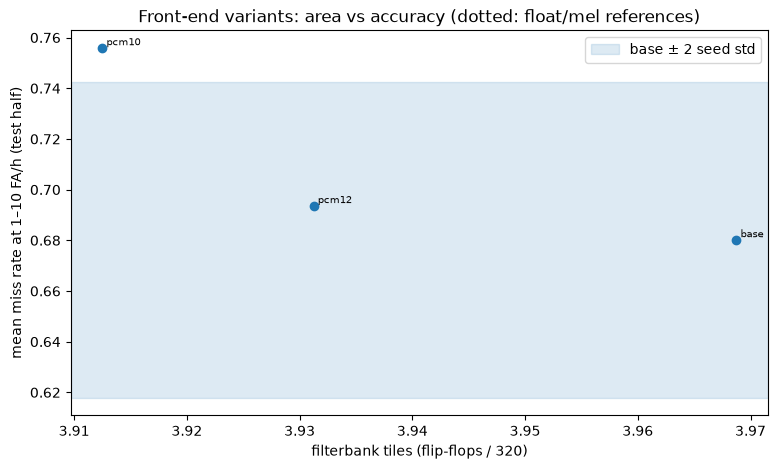

In [5]:
if len(fe):
    fig, ax = plt.subplots(figsize=(9, 5))
    a = agg.dropna(subset=["ff"])
    ax.scatter(a["ff"] / 320, a["score"])
    for v, r in a.iterrows():
        ax.annotate(v, (r["ff"] / 320, r["score"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
    for v, r in agg[agg["ff"].isna()].iterrows():
        ax.axhline(r["score"], ls=":", lw=0.8, color="gray")
        ax.annotate(v, (ax.get_xlim()[0], r["score"]), fontsize=7, color="gray")
    if len(base) > 1:
        ax.axhspan(base.mean() - 2 * base.std(), base.mean() + 2 * base.std(), alpha=0.15, color="C0", label="base ± 2 seed std")
    ax.set(xlabel="filterbank tiles (flip-flops / 320)", ylabel="mean miss rate at 1–10 FA/h (test half)",
           title="Front-end variants: area vs accuracy (dotted: float/mel references)")
    ax.legend()
    plt.show()

### F2 · The low-noise version: 66-word classification on held-out voices

Wake-word miss rates at a few false alarms per hour swing by ±5 points between seeds (three
`base` seeds above), too noisy to rank front ends that differ by a few points. So every
variant also trains the same TCN body to classify all 66 candidate words (300 train-voice
clips per word, simulator train mode) and is tested on 6,600 held-out-voice clips in
simulator test mode (held-out rooms and ambience). Seed-to-seed spread of `base`: 0.3 points.
A front end that throws speech information away loses accuracy here, whatever the detector.

,acc,n,ff,frame_ms,d_acc_pts,ff_saved,tiles_saved
variant,,,,,,,
mel40_10ms,0.560,1,NaN,10.0,3.598,NaN,NaN
ford4pow,0.557,1,NaN,16.0,3.341,NaN,NaN
mel40,0.556,1,NaN,16.0,3.235,NaN,NaN
mel16,0.556,1,NaN,16.0,3.220,NaN,NaN
lean5o4,0.552,2,1616.0,16.0,2.826,-346.0,-1.081
...,...,...,...,...,...,...,...
acc16,0.446,1,1142.0,16.0,-7.795,128.0,0.400
yw14,0.429,1,998.0,16.0,-9.417,272.0,0.850
yw12,0.361,1,930.0,16.0,-16.295,340.0,1.062


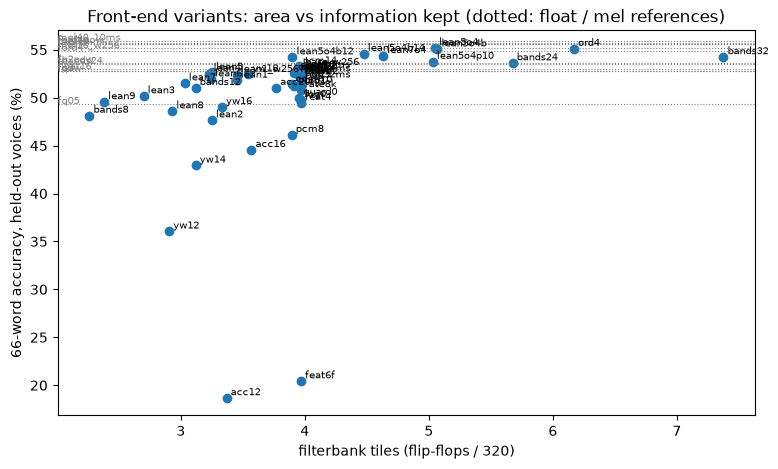

In [6]:
mrows = []
for f in sorted((R / "multi").glob("*.json")):
    r = json.loads(f.read_text())
    w = r.get("width", 64)
    mrows.append({"variant": r["variant"] + ("" if w == 64 else f"_w{w}"), "seed": r["seed"], "acc": r["test_acc"], "ff": r["ff"],
                  "frame_ms": r["frame_ms"]})
multi = pd.DataFrame(mrows)
if len(multi):
    m = multi.groupby("variant").agg(acc=("acc", "mean"), n=("seed", "size"), ff=("ff", "first"),
                                     frame_ms=("frame_ms", "first"))
    b = m.loc["base", "acc"]
    m["d_acc_pts"] = 100 * (m["acc"] - b)
    m["ff_saved"] = 1270 - m["ff"]
    m["tiles_saved"] = m["ff_saved"] / 320
    display(m.sort_values("acc", ascending=False).round(3))

    fig, ax = plt.subplots(figsize=(9, 5))
    a = m.dropna(subset=["ff"])
    ax.scatter(a["ff"] / 320, 100 * a["acc"])
    for v, r in a.iterrows():
        ax.annotate(v, (r["ff"] / 320, 100 * r["acc"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
    for v, r in m[m["ff"].isna()].iterrows():
        ax.axhline(100 * r["acc"], ls=":", lw=0.8, color="gray")
        ax.annotate(v, (ax.get_xlim()[0], 100 * r["acc"]), fontsize=7, color="gray")
    ax.set(xlabel="filterbank tiles (flip-flops / 320)", ylabel="66-word accuracy, held-out voices (%)",
           title="Front-end variants: area vs information kept (dotted: float / mel references)")
    plt.show()

### The bigger area lever: move the filter state off chip

Bit cuts shave flip-flops at the margins: the filterbank's area is **per-band state**
(2 filter registers + 1 accumulator per band, 68 bits today), and that only shrinks so far
before accuracy drops (`yw16`, `acc16`, `bands8` above). Measured module areas (yosys,
today's RTL): filterbank 1,266 FF / 3,353 cells, CIC 150 / 1,069, ring buffer 185 / 992,
VAD 20 / 407.

An architectural alternative (not built, estimate):
* the PSRAM ring buffer (`src/audio_ring.v`) already holds the last seconds of PCM;
* once per 16 ms frame, filter each band over the frame's 256 samples read back from PSRAM,
  with the band's 2 filter registers loaded from / stored to PSRAM as well (8 B per band);
* on chip: one band's working registers (~70 FF) + a parallel 16×16 multiplier (~0.5 tile)
  instead of 16 × 68 FF of state: **~4 tiles → ~1–1.5 tiles**;
* cost: QSPI bus time, 16 × (512 + 8) B per 16 ms ≈ 0.52 MB/s, **~13% of the bus** that
  otherwise streams classifier weights (65 kB/frame at 8-bit, stride 1); 40 bands ≈ 32%.
* PSRAM CE# low time is limited to 8 µs (APS6404L), so reads go in short bursts; the
  ring buffer's write path already does this.

With state off chip, the band count becomes a bandwidth question instead of an area
question, which is what makes 24–40 bands affordable if the probes show they help.

## P5 · Pretrained speech embedding + head trained on our data

Google's speech_embedding (openWakeWord's frozen backbone, mel front end, ~330k+ params) with
a small MLP head trained on the same simulated telescope windows as the TCN probes, scored
on the same streams. Read against `base` in F: same data, same metric.

## P6 · Distillation: a chip-sized student learns the embedding from chip features

The student (causal TCN on the chip front end's features, one output per 32 ms) is
trained to output the teacher's embedding on simulated audio only; then the same head is
trained on the student's embeddings. `student_val_cos`: cosine between student and teacher
embeddings on held-out voices/rooms/ambience (`multi_test`), a front-end fidelity measure.

In [7]:
erows = []
for f in sorted(R.glob("embed_*.json")):
    r = json.loads(f.read_text())
    erows.append({"run": f.stem.replace("embed_telescope", ""), "student_fe": r.get("fe"), "student_params": r.get("student_params"),
                  "student_cos": r.get("student_val_cos"), "head_params": r["head_params"],
                  **{f"frr@{fa}": r[f"frr@{fa}"] for fa in FAS}, "real_fa@5": r["real_fa@5.0"]})
if len(fe):
    b = fe[fe.variant == "base"]
    erows.append({"run": "TCN from scratch (F base, mean of seeds)", "student_fe": "base",
                  "student_params": int(b["params"].iloc[0]),
                  **{f"frr@{fa}": b[f"frr@{fa}"].mean() for fa in FAS}, "real_fa@5": None})
display(pd.DataFrame(erows).round(3))

,run,student_fe,student_params,student_cos,head_params,frr@0.5,frr@1.0,frr@2.0,frr@5.0,frr@10.0,real_fa@5
0,_h64d3_s0,None,NaN,NaN,65985.0,0.842,0.680,0.481,0.242,0.192,4.77
1,_s0,None,NaN,NaN,140161.0,0.768,0.660,0.441,0.249,0.199,5.17
2,_student_base_w128_x_s0,base,154848.0,0.764,65985.0,0.896,0.640,0.434,0.290,0.256,5.57
3,_student_base_w192_x_s0,base,330528.0,0.788,65985.0,0.788,0.643,0.448,0.316,0.253,5.04
4,_student_base_w32_x_s0,base,14208.0,0.625,65985.0,0.896,0.798,0.623,0.448,0.364,2.39
5,_student_base_w64_s0,base,44704.0,0.683,65985.0,0.771,0.663,0.495,0.327,0.279,2.25
6,_student_base_w64_x_s0,base,44704.0,0.700,65985.0,0.882,0.657,0.455,0.337,0.290,4.11
7,_student_float16_w64_x_s0,float16,44704.0,0.704,65985.0,0.828,0.657,0.471,0.340,0.296,4.77
8,_student_lean5_w64_x_s0,lean5,44704.0,0.696,65985.0,0.892,0.697,0.465,0.337,0.290,3.32
9,_student_lean5o4_w64_x_s0,lean5o4,44704.0,0.715,65985.0,0.815,0.562,0.471,0.313,0.273,4.38


## What to do next

1. **Distillation as the training recipe.** Teacher embeddings for the full v3 simulated set
   (all words, conversation, ambience), student on chip features (`lean5o4`), then a
   first-stage head per word; sweep student width against the 16-tile budget (stride 2–4,
   4-bit weights). Try distilling the teacher *head* (keyword posterior) as well as the
   embedding, and a bigger teacher (Whisper encoder frames) if the embedding saturates.
2. **RTL:** `filterbank.v` with the `lean5` widths and the second resonator (state 4×18 +
   20 bits/band, Q2.8 coefficients, 6-bit codes at 1/4 octave); regenerate coefficients;
   bit-exact against `frontend_var.features(v)`; yosys area check.
3. **Test mix:** report miss rates by distance/SNR bucket next to the pooled number, so we
   can read results against published near-field numbers.
4. **PSRAM-state filterbank:** estimate bus contention against the classifier's weight
   stream before committing.